# 05 — Reconnaissance / inférence sur des images brutes
Module `src/inference.py`, script `predict.py`.

```
image brute → prétraitement (gris, médian, normalisation, alignement) → caractéristiques des zones
            → scores des zones (ensemble de 5 modèles) → score d'image
            → DÉCISION : score > seuil → ANOMALIE, sinon NORMALE
            → LOCALISATION : carte de chaleur des zones, reprojetée sur l'image d'origine
              (inverse de la transformation d'alignement, Ch. 2)
            → DESCRIPTION (Ch. 3) : carte binarisée (z > 3) → contours → boîte, aire, centroïde
```
Ce notebook part des **fichiers image** du test, et non du cache de caractéristiques. Il vérifie donc la chaîne complète, telle qu'elle serait utilisée en production.

In [1]:
import sys, time, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from src.data_loader import load_config, get_splits, load_mask
from src.inference import Inspector, render

cfg = load_config(ROOT / "config.yaml"); CATS = cfg["data"]["categories"]
OUT = ROOT / "results" / "05_inference"; OUT.mkdir(parents=True, exist_ok=True)
INSP = {c: Inspector.for_category(c, cfg) for c in CATS}
TEST = {c: get_splits(c, cfg)["test"] for c in CATS}
print({c: f"seuil {INSP[c].det.threshold_:.2f}" for c in CATS})

C:\Users\Admin\Desktop\S9\Computer vision\projet_computer_vision\Visual Anomaly Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'bottle': 'seuil 1.92', 'hazelnut': 'seuil 1.68', 'carpet': 'seuil 1.85'}


## 1. Inférence sur tout le jeu de test (à partir des images brutes)

In [2]:
PRED = {}
for c in CATS:
    PRED[c] = [INSP[c].predict(x.path) for x in tqdm(TEST[c], desc=c)]
rows = []
for c in CATS:
    y = np.array([x.label for x in TEST[c]]); p = np.array([pr.is_anomaly for pr in PRED[c]]).astype(int)
    t = np.array([pr.time_ms for pr in PRED[c]])
    rows.append({"catégorie": c, "images": len(y), "sains rejetés": f"{((p == 1) & (y == 0)).sum()}/{(y == 0).sum()}",
                 "défauts détectés": f"{((p == 1) & (y == 1)).sum()}/{(y == 1).sum()}",
                 "temps moyen (ms/image)": round(t.mean()), "temps max (ms)": round(t.max())})
df_inf = pd.DataFrame(rows).set_index("catégorie"); df_inf.to_csv(OUT / "inference_test.csv"); df_inf

bottle:   0%|          | 0/83 [00:00<?, ?it/s]

bottle:   1%|          | 1/83 [00:00<00:26,  3.07it/s]

bottle:   2%|▏         | 2/83 [00:00<00:25,  3.16it/s]

bottle:   4%|▎         | 3/83 [00:00<00:25,  3.15it/s]

bottle:   5%|▍         | 4/83 [00:01<00:25,  3.11it/s]

bottle:   6%|▌         | 5/83 [00:01<00:25,  3.09it/s]

... (249 outputs left out)

carpet:  98%|█████████▊| 115/117 [00:10<00:00, 10.64it/s]

carpet: 100%|██████████| 117/117 [00:10<00:00, 10.67it/s]

carpet: 100%|██████████| 117/117 [00:10<00:00, 10.86it/s]

,images,sains rejetés,défauts détectés,temps moyen (ms/image),temps max (ms)
catégorie,,,,,
bottle,83,3/20,61/63,323,398
hazelnut,110,6/40,51/70,1354,1815
carpet,117,1/28,35/89,92,149


Ces décisions doivent être **identiques** à celles du notebook 04, qui partait des caractéristiques en cache : c'est la vérification que la chaîne d'inférence reproduit exactement celle de l'apprentissage.

In [3]:
from src.features import compute_features
for c in CATS:
    f = compute_features(c, cfg, verbose=False); det = INSP[c].det
    s_cache = det.score_features(f["test"]["zones"], f["test"]["global"])[0]
    s_raw = np.array([pr.score for pr in PRED[c]])
    print(f"{c:9s} écart max des scores (image brute vs cache) : {np.abs(s_cache - s_raw).max():.1e} | "
          f"décisions identiques : {np.array_equal(s_cache > det.threshold_, s_raw > det.threshold_)}")

bottle    écart max des scores (image brute vs cache) : 2.4e-07 | décisions identiques : True


hazelnut  écart max des scores (image brute vs cache) : 1.9e-07 | décisions identiques : True


carpet    écart max des scores (image brute vs cache) : 0.0e+00 | décisions identiques : True


## 2. Exemples : une image saine et un exemple par type de défaut
Contour **vert** = vérité terrain ; boîtes **rouges** = régions signalées par le détecteur (seulement si l'image est jugée anormale).

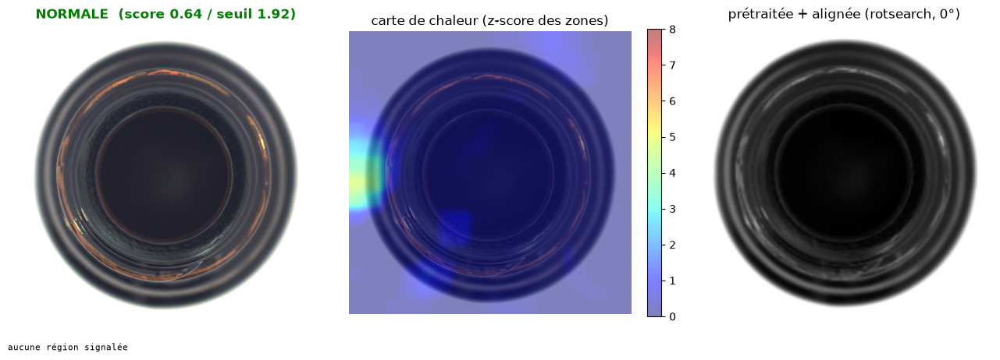

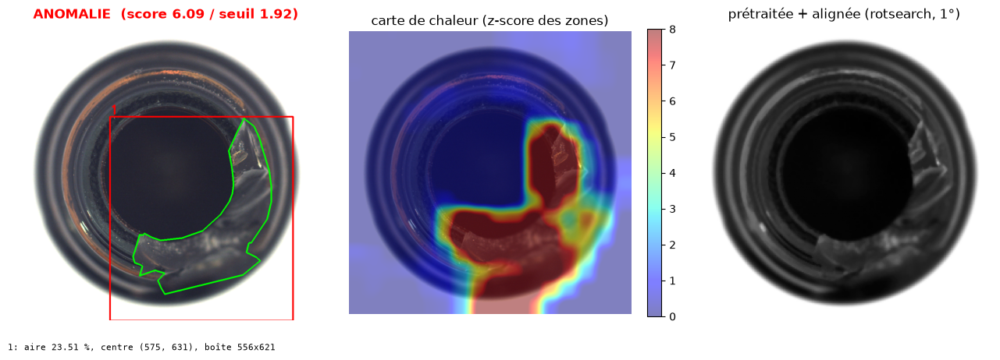

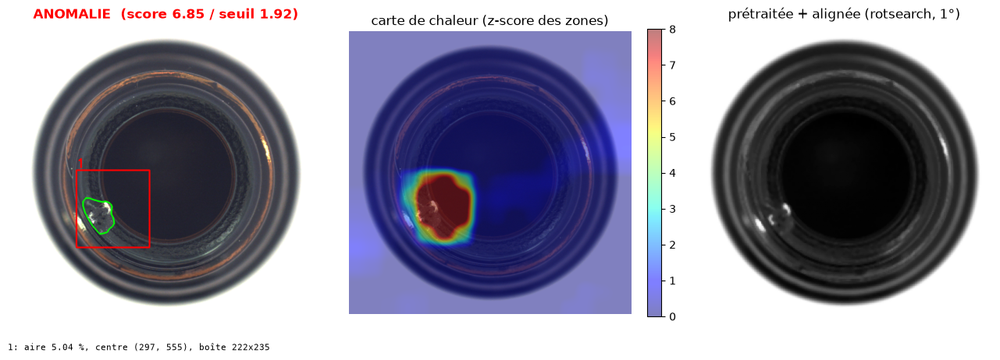

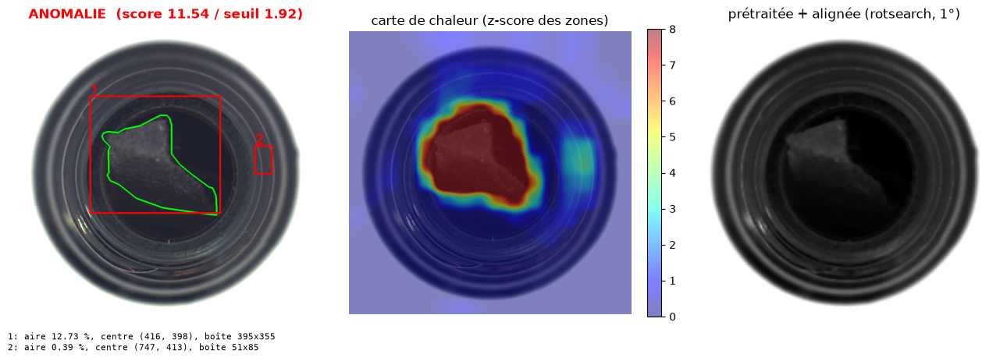

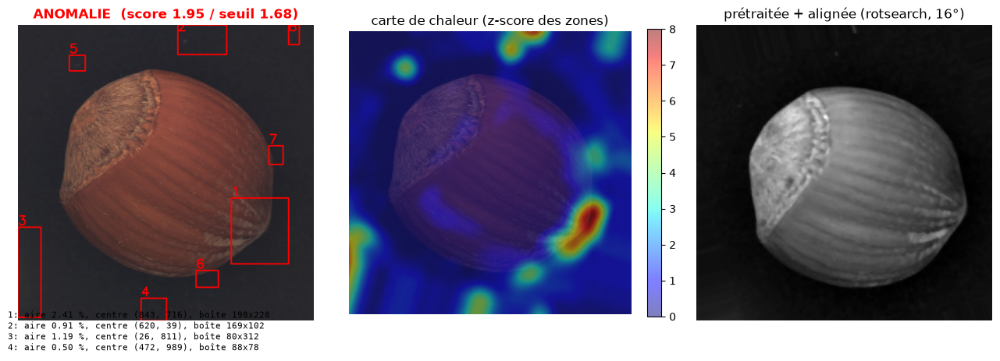

...

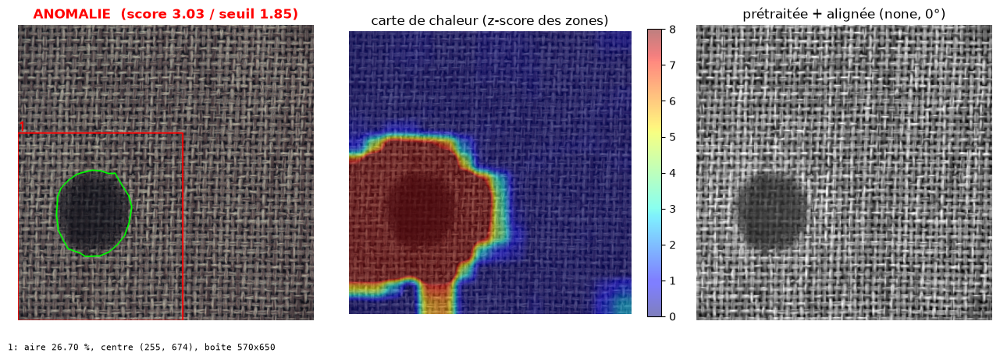

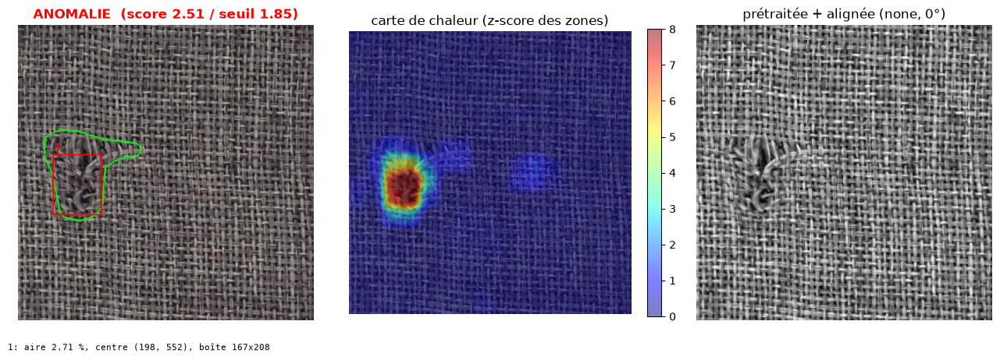

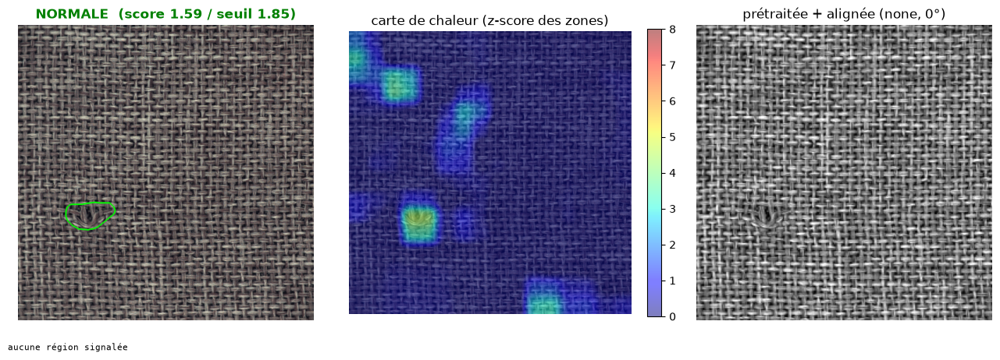

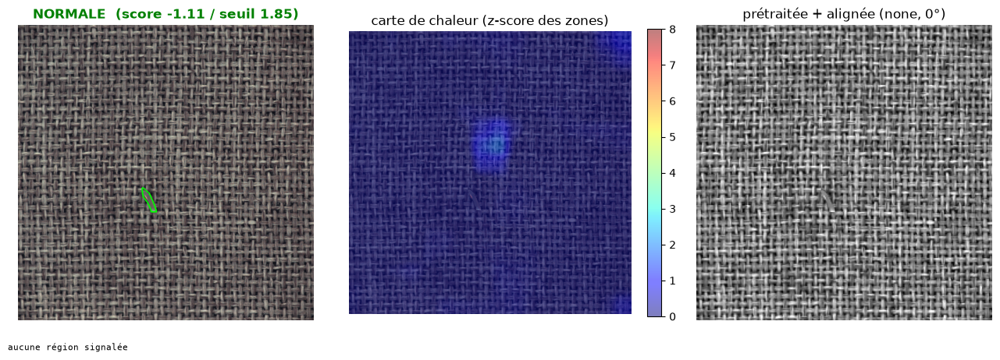

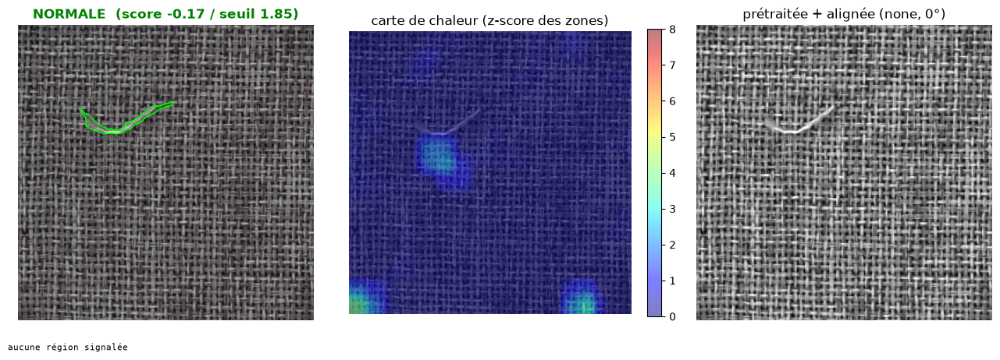

,catégorie,vérité,décision,score,seuil,nb régions,surface défaut %,temps (ms),région 1 sur le défaut
0,bottle,good,NORMALE,0.644,1.922,0,0.00,319.5,—
1,bottle,broken_large,ANOMALIE,6.088,1.922,1,23.51,325.8,oui
2,bottle,broken_small,ANOMALIE,6.850,1.922,1,5.04,316.8,oui
3,bottle,contamination,ANOMALIE,11.542,1.922,2,13.12,393.1,oui
4,hazelnut,good,ANOMALIE,1.946,1.677,8,5.88,1614.8,—
5,hazelnut,crack,ANOMALIE,3.981,1.677,4,10.28,1298.1,oui
6,hazelnut,cut,NORMALE,1.195,1.677,0,0.00,1284.8,—
7,hazelnut,hole,ANOMALIE,3.226,1.677,4,4.79,1359.5,oui
8,hazelnut,print,ANOMALIE,4.093,1.677,4,17.08,1344.5,oui
9,carpet,good,NORMALE,-1.024,1.851,0,0.00,86.1,—


In [4]:
def gt(x):
    return load_mask(x) if x.label else None
rows = []
for c in CATS:
    test = TEST[c]
    picks = [next(i for i, x in enumerate(test) if x.label == 0)]
    picks += [next(i for i, x in enumerate(test) if x.defect == d) for d in sorted({x.defect for x in test if x.label})]
    for i in picks:
        x, pr = test[i], PRED[c][i]
        render(pr, gt_mask=gt(x), path=OUT / f"{c}_{x.defect}_{x.path.stem}.png", show=True)
        m = gt(x)
        hit = None
        if m is not None and pr.regions:
            bx, by, bw, bh = pr.regions[0].bbox
            hit = bool(m[by:by + bh, bx:bx + bw].any())
        rows.append({"catégorie": c, "vérité": x.defect, **pr.summary(),
                     "région 1 sur le défaut": "—" if hit is None else ("oui" if hit else "non")})
pd.DataFrame(rows).to_csv(OUT / "exemples.csv", index=False); pd.DataFrame(rows)

## 3. Localisation : la région n° 1 tombe-t-elle sur le vrai défaut ?
Pour chaque défaut **détecté**, on vérifie si la boîte de la région la plus anormale recouvre le masque vérité terrain. Les mesures pixel par pixel (AUROC pixel, IoU) viendront à l'étape 8.

In [5]:
rows = []
for c in CATS:
    hits, n_det = [], 0
    for x, pr in zip(TEST[c], PRED[c]):
        if x.label and pr.is_anomaly and pr.regions:
            n_det += 1; m = load_mask(x); bx, by, bw, bh = pr.regions[0].bbox
            hits.append(m[by:by + bh, bx:bx + bw].any())
    rows.append({"catégorie": c, "défauts détectés avec région": n_det,
                 "région n° 1 sur le défaut": f"{np.mean(hits):.0%}" if hits else "—",
                 "régions par image (moyenne)": round(np.mean([len(pr.regions) for x, pr in zip(TEST[c], PRED[c]) if x.label and pr.is_anomaly]), 1)})
df_loc = pd.DataFrame(rows).set_index("catégorie"); df_loc.to_csv(OUT / "localisation_region1.csv"); df_loc

,défauts détectés avec région,région n° 1 sur le défaut,régions par image (moyenne)
catégorie,,,
bottle,61,100%,1.5
hazelnut,51,94%,2.2
carpet,35,80%,2.1


## 4. Erreurs : une fausse alarme et un défaut manqué par catégorie
Montrer les erreurs aide à comprendre les limites du détecteur.

bottle — fausse alarme la plus forte : 019.png


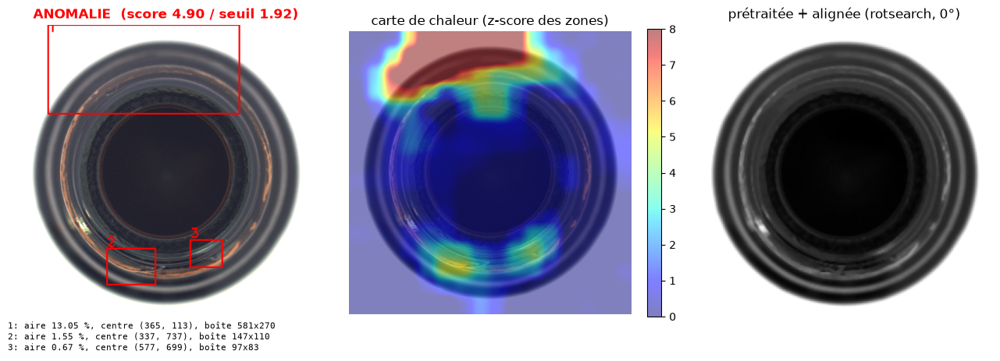

bottle — défaut le plus manqué : contamination 019.png


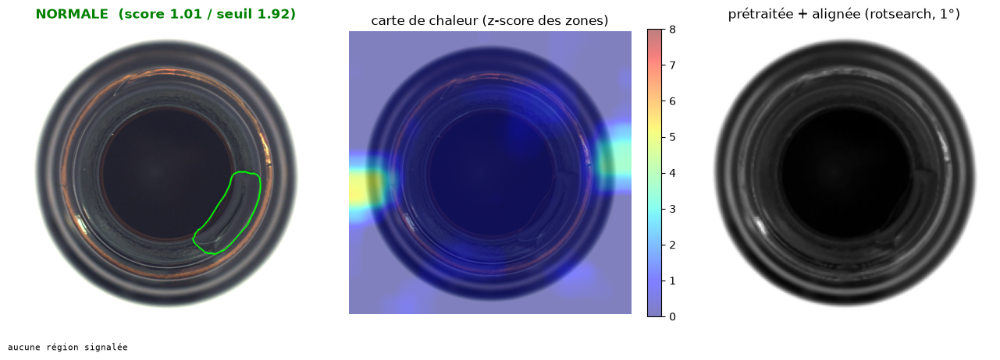

hazelnut — fausse alarme la plus forte : 039.png


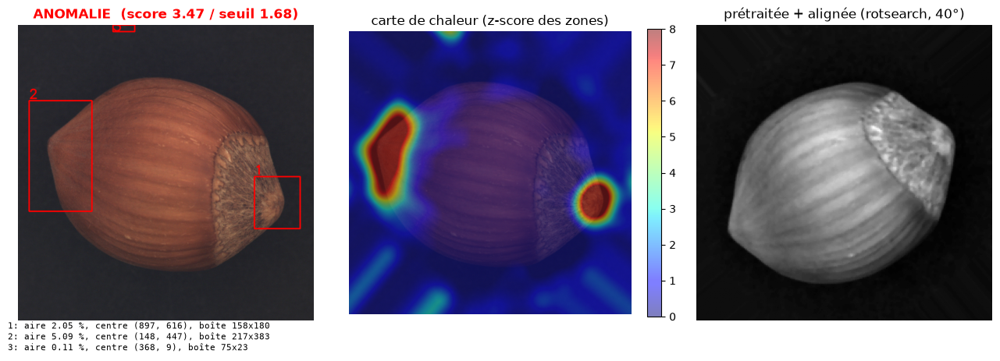

hazelnut — défaut le plus manqué : crack 013.png


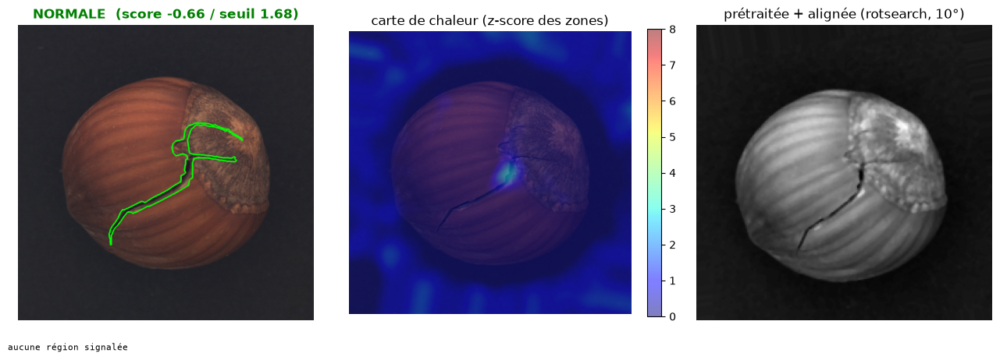

carpet — fausse alarme la plus forte : 020.png


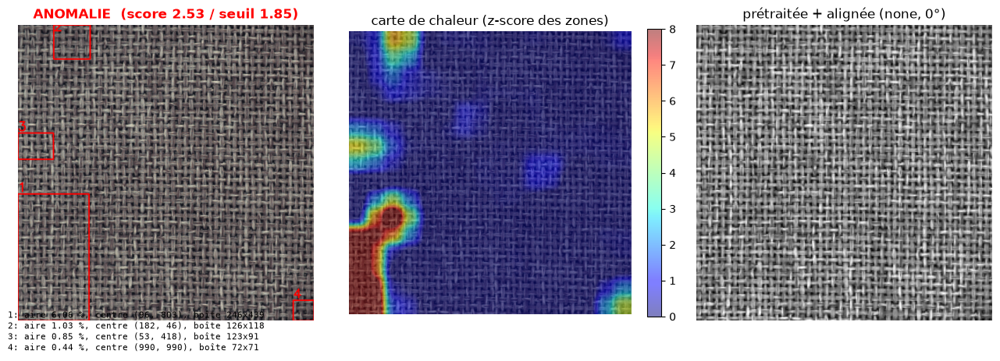

carpet — défaut le plus manqué : thread 002.png


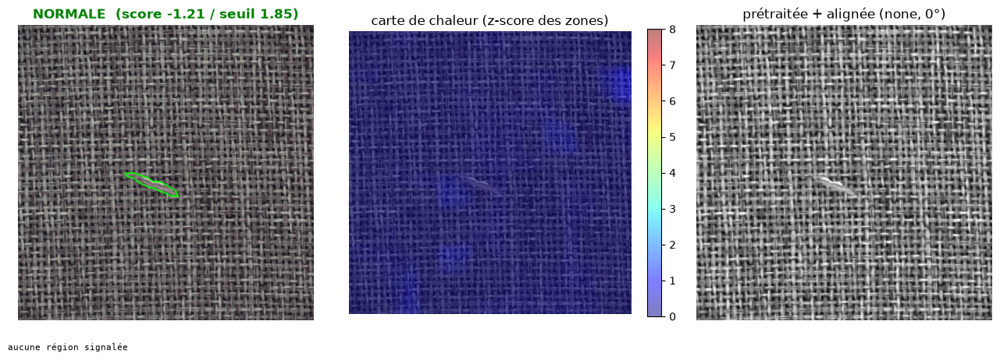

In [6]:
for c in CATS:
    test, preds = TEST[c], PRED[c]
    fa = [i for i, (x, p) in enumerate(zip(test, preds)) if x.label == 0 and p.is_anomaly]
    miss = [i for i, (x, p) in enumerate(zip(test, preds)) if x.label == 1 and not p.is_anomaly]
    if fa:
        i = max(fa, key=lambda i: preds[i].score); print(f"{c} — fausse alarme la plus forte : {test[i].path.name}")
        render(preds[i], path=OUT / f"erreur_{c}_fausse_alarme.png", show=True)
    else:
        print(f"{c} — aucune fausse alarme sur le test")
    if miss:
        i = min(miss, key=lambda i: preds[i].score); print(f"{c} — défaut le plus manqué : {test[i].defect} {test[i].path.name}")
        render(preds[i], gt_mask=load_mask(test[i]), path=OUT / f"erreur_{c}_defaut_manque.png", show=True)

## 5. Utilisation en ligne de commande (`predict.py`)

In [7]:
cmd = [sys.executable, "-W", "ignore", str(ROOT / "predict.py"), "--category", "bottle",
       "--image", str(ROOT / "data/mvtec/bottle/test/broken_large/000.png"), str(ROOT / "data/mvtec/bottle/test/good/000.png")]
r = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", cwd=ROOT,
                   env={**__import__("os").environ, "PYTHONIOENCODING": "utf-8"})
print(r.stdout or r.stderr)

000.png                        ANOMALIE  score   6.09 (seuil 1.92)    355 ms
    région 1: boîte x=280 y=279 556x621 px | aire 23.51 % | centroïde (575, 631) | z max 17.0
    -> C:\Users\Admin\Desktop\S9\Computer vision\projet_computer_vision\Visual Anomaly Detection\results\predictions\bottle\broken_large_000.png
000.png                        NORMALE   score   0.64 (seuil 1.92)    446 ms
    -> C:\Users\Admin\Desktop\S9\Computer vision\projet_computer_vision\Visual Anomaly Detection\results\predictions\bottle\good_000.png



## Conclusions de l'étape 7

**1. La chaîne d'inférence reproduit exactement l'apprentissage.** Partir des fichiers image donne les mêmes scores que le cache (écart inférieur à 10⁻⁶) et **les mêmes décisions** pour les 310 images de test.

**2. Décisions sur le test** (seuil = 95e centile des scores hors-pli des images saines) :

| | sains rejetés | défauts détectés | temps moyen |
|---|---|---|---|
| bottle | 3/20 | 61/63 | ~0,3 s |
| hazelnut | 6/40 | 51/70 | ~1,4 s (961 zones × 5 modèles) |
| carpet | 1/28 | 35/89 | ~0,1 s |

**3. Localisation.** Quand un défaut est détecté, la région la plus anormale (n° 1) tombe sur le vrai défaut dans **100 %** (bottle), **94 %** (hazelnut) et **80 %** (carpet) des cas.

**4. Limites observées :**
- **Les boîtes sont plus grandes que les défauts.** La carte de chaleur a la résolution des zones (32 ou 16 pixels sur 256) et elle est lissée. L'**aire** annoncée est donc une **surestimation**. La précision pixel par pixel est mesurée à l'étape 8.
- Hazelnut est la catégorie la plus lente : 961 zones, et un modèle par position pour chacun des 5 plis.
- **Défauts les plus manqués :** les coupures fines de hazelnut (`cut`, 0,8 % de l'image) ; la contamination métallique (0,4 %), les fils et les trous de carpet.